In [ ]:
# %pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np
import pandas as pd
import wfdb
import os
import sys
from scipy import signal
from scipy.signal import butter, filtfilt
from wfdb.processing import resample_singlechan
import matplotlib.pyplot as plt
import pywt
import json
import glob
import random
from scipy.io import loadmat

In [30]:
def butter_bandpass(lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a
 
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = filtfilt(b, a, data)
    return y

def calc_baseline(signal):
    ssds = np.zeros((3))
    cur_lp = np.copy(signal)
    iterations = 0
    while True:
        # Decompose 1 level
        lp, hp = pywt.dwt(cur_lp, "db4")

        # Shift and calculate the energy of detail/high pass coefficient
        ssds = np.concatenate(([np.sum(hp ** 2)], ssds[:-1]))

        # Check if we are in the local minimum of energy function of high-pass signal
        if ssds[2] > ssds[1] and ssds[1] < ssds[0]:
            break

        cur_lp = lp[:]
        iterations += 1

    # Reconstruct the baseline from this level low pass signal up to the original length
    baseline = cur_lp[:]
    for _ in range(iterations):
        baseline = pywt.idwt(baseline, np.zeros((len(baseline))), "db4")

    return baseline[: len(signal)]

def preprocessing(ecg):
    ecg = signal.savgol_filter(ecg, 25, 3)
    ecg = (ecg - ecg.min()) / (ecg.max() - ecg.min())
    return ecg

In [31]:
afib = set([100, 101, 103, 105, 108, 109, 111, 112, 201, 202, 203, 210, 217, 219, 221, 222])

In [17]:
%matplotlib qt5

cur_dir = os.getcwd()
db_dir = os.path.join(cur_dir, 'data', 'WFDB_ChapmanShaoxing')

def most_frequent(List):
    return max(set(List), key=List.count)

for file in os.listdir(db_dir):
    if file.endswith('.hea'):
        record_name = os.path.splitext(file)[0]
        record_path = os.path.join(db_dir, record_name)
        data = loadmat(record_path + '.mat')['val']
        with open(record_path + '.hea', 'r') as f:
            header_data = f.readlines()
        fig, axes = plt.subplots(12, 1)
        for i in range(12):
            axes[i].plot(data[i,:])
        plt.show()
        break

In [115]:
# SEGMENTATE THE WINDOW WITH 6sec and 256hz
%matplotlib qt5

cur_dir = os.getcwd()
db_dir = os.path.join(cur_dir, 'data', 'mitdb')

def most_frequent(List):
    return max(set(List), key=List.count)

for file in os.listdir(db_dir):
    if file.endswith('.hea'):
        record_name = os.path.splitext(file)[0]
        record_path = os.path.join(db_dir, record_name)

        # if int(record_name) not in afib:
        #     continue

        record = wfdb.rdrecord(record_path)
        ann = wfdb.rdann(record_path, extension='atr')

        original_signal = record.p_signal.T[0]

        original_fs = record.fs
        target_fs = 256
        step = 6

        original_signal, ann = resample_singlechan(original_signal, ann, original_fs, target_fs)

        window_size = target_fs * step
        signal_length = len(original_signal)
        label = np.array(ann.aux_note)
        sample = ann.sample
        for i in range(1, len(label)):
            if(label[i] == ''):
                label[i] = label[i - 1]
        X = []
        y = []

        # FOR AFDB
        # for i, segment_label in enumerate(label):
        #     segment_label = segment_label[1:]
        #     if segment_label == 'AFIB':
        #         start = sample[i]
        #         end_idx = 0
        #         if i == len(label) - 1:
        #             end_idx = start + 5 * window_size
        #         else:
        #             end_idx = sample[i + 1]
        #         for start_idx in range(start, end_idx, target_fs * 5):
        #             segment_signal = original_signal[start_idx:start_idx+window_size]
        #             filtered_signal = preprocessing(segment_signal)
        #             X.append(list(filtered_signal))
        #             y.append(segment_label)
        #     elif segment_label == 'N':
        #         start = sample[i]
        #         end = start + window_size * 500
        #         if i + 1 < len(label):
        #             if label[i + 1] == '(AFIB':
        #                 end = min(end, sample[i + 1])
        #         else:
        #             end = start + window_size * 100
        #         for start_idx in range(start, end, window_size):
        #             segment_signal = original_signal[start_idx:start_idx+window_size]
        #             filtered_signal = preprocessing(segment_signal)
        #             X.append(list(filtered_signal))
        #             y.append(segment_label)
        # break
        # # FOR MITDB
        for start_idx in range(0, signal_length - window_size, window_size):
            end_idx = start_idx + window_size
            beat_label = label[np.flatnonzero((sample >= start_idx) & (sample <= end_idx))]
            segment_signal = original_signal[start_idx:end_idx]
            filtered_signal = preprocessing(segment_signal)
            
            segment_label = most_frequent(list(beat_label))[1:]

            if segment_label == 'N' or segment_label == 'AFIB':
                X.append(list(filtered_signal))
                y.append(segment_label)

        X = np.array(X)
        y = np.array(y)
        np.save(os.path.join(os.getcwd(), 'data', 'afib', f'{record_name}.npy'), X)
        np.save(os.path.join(os.getcwd(), 'data', 'afib', f'{record_name}_label.npy'), y)

# INSIGHTS ABOUT THE LABELS

In [116]:
train_set = set([100, 101, 103, 105, 108, 109, 111, 112, 201, 202, 203, 210, 217, 219, 221, 222])

In [3]:
y = []
studies = []
for filepath in glob.glob(os.path.join(os.getcwd(), 'data', 'afib', '*_label.npy')):
    filename = filepath.split('\\')[-1][:]
    y.append(np.load(filepath))
    studies.append(filename[:filename.find('_')])
studies

['04015',
 '04043',
 '04048',
 '04126',
 '04746',
 '04908',
 '04936',
 '05091',
 '05121',
 '05261',
 '06426',
 '06453',
 '06995',
 '07162',
 '07859',
 '07879',
 '07910',
 '08215',
 '08219',
 '08378',
 '08405',
 '08434',
 '08455',
 '100',
 '101',
 '102',
 '103',
 '104',
 '105',
 '106',
 '107',
 '108',
 '109',
 '111',
 '112',
 '113',
 '114',
 '115',
 '116',
 '117',
 '118',
 '119',
 '121',
 '122',
 '123',
 '124',
 '200',
 '201',
 '202',
 '203',
 '205',
 '207',
 '208',
 '209',
 '210',
 '212',
 '213',
 '214',
 '215',
 '217',
 '219',
 '220',
 '221',
 '222',
 '223',
 '228',
 '230',
 '231',
 '232',
 '233',
 '234']

['233',
 '103',
 '220',
 '202',
 '118',
 '217',
 '207',
 '221',
 '113',
 '222',
 '08215',
 '109',
 '112',
 '05091',
 '100',
 '208',
 '228',
 '111',
 '232',
 '121',
 '04936',
 '04746',
 '06995',
 '04043',
 '06453',
 '101',
 '212',
 '08378',
 '08434',
 '102',
 '119',
 '08405',
 '107',
 '106',
 '104',
 '04015',
 '231',
 '07879',
 '203',
 '05121',
 '213',
 '07910',
 '114',
 '234',
 '04126',
 '201',
 '123',
 '223',
 '205',
 '209',
 '04908',
 '200',
 '210',
 '116',
 '117',
 '108',
 '08455',
 '122',
 '230',
 '07859',
 '105',
 '04048',
 '214',
 '07162',
 '06426',
 '115',
 '124',
 '08219',
 '219',
 '05261',
 '215']

In [43]:
random.shuffle(studies)
studies
threshold = int(len(studies) * 0.7)
train_studies = studies[:threshold]
test_studies = studies[threshold:]

In [48]:
split = {}
split['train'] = train_studies
split['test'] = test_studies

In [49]:
with open("split.json", 'w') as f:
    json.dump(split, f)

In [47]:
import torch
torch.__version__

'2.4.1'

In [44]:
train_y = []
test_y = []
for filepath in glob.glob(os.path.join(os.getcwd(), 'data', 'afib', '*_label.npy')):
    filename = filepath.split('\\')[-1][:]
    filename = filename[:filename.find('_')]
    if filename in train_studies:
        train_y.append(np.load(filepath))
    else:
        test_y.append(np.load(filepath))
train_y = np.concatenate(train_y)
test_y = np.concatenate(test_y)
df = pd.DataFrame(train_y)
df_2 = pd.DataFrame(test_y)
df[0] = df[0].astype("string")
df_2[0] = df_2[0].astype("string")
print(df[0].value_counts(), df_2[0].value_counts())

0
N       26515
AFIB    25003
Name: count, dtype: Int64 0
N       13319
AFIB     8308
Name: count, dtype: Int64


<Axes: xlabel='0'>

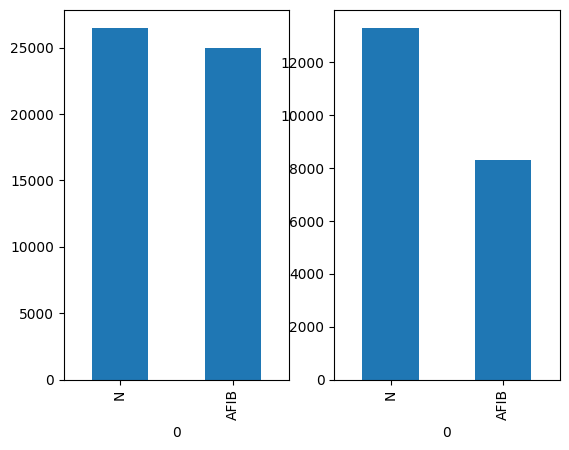

In [45]:
%matplotlib inline
plt.subplot(1, 2, 1)
df[0].value_counts().plot(kind = 'bar')
plt.subplot(1, 2, 2)
df_2[0].value_counts().plot(kind = 'bar')